In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [11]:
df = pd.read_csv('bike_hours_clean.csv', parse_dates=["service_date"])
df

,record_id,service_date,station,hour,forecast_temp_c,forecast_rain,departures
0,2072,2026-08-27,Market,20,30.0,False,9
1,2595,2026-09-02,Harbor,11,24.0,False,6
2,561,2026-08-09,Park,7,28.0,False,7
3,3258,2026-09-10,Park,16,26.0,False,11
4,4059,2026-09-20,Riverside,19,19.0,False,7
...,...,...,...,...,...,...,...
4620,279,2026-08-06,Riverside,19,23.0,False,11
4621,2801,2026-09-05,University,7,30.0,False,14
4622,1338,2026-08-18,Harbor,14,16.0,True,4
4623,407,2026-08-07,Harbor,7,25.0,False,13


In [12]:
# to boolan
df["forecast_rain"] = (
    df["forecast_rain"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({"true":True, "false":False})
)
assert df["forecast_rain"].notna().all()

In [13]:
df["day_type"] = np.where(
    df["service_date"].dt.dayofweek < 5,
    "Weekday",
    "Weekend"
)
df

,record_id,service_date,station,hour,forecast_temp_c,forecast_rain,departures,day_type
0,2072,2026-08-27,Market,20,30.0,False,9,Weekday
1,2595,2026-09-02,Harbor,11,24.0,False,6,Weekday
2,561,2026-08-09,Park,7,28.0,False,7,Weekend
3,3258,2026-09-10,Park,16,26.0,False,11,Weekday
4,4059,2026-09-20,Riverside,19,19.0,False,7,Weekend
...,...,...,...,...,...,...,...,...
4620,279,2026-08-06,Riverside,19,23.0,False,11,Weekday
4621,2801,2026-09-05,University,7,30.0,False,14,Weekend
4622,1338,2026-08-18,Harbor,14,16.0,True,4,Weekday
4623,407,2026-08-07,Harbor,7,25.0,False,13,Weekday


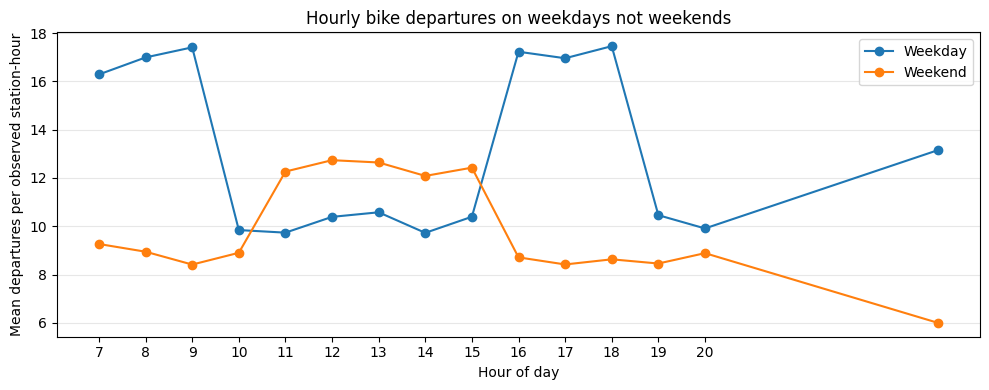

In [14]:
hourly = (
    df.groupby(["hour","day_type"])["departures"]
    .mean()
    .unstack("day_type")
    .sort_index()
)

fig,ax = plt.subplots(figsize=(10,4))

for day_type in ["Weekday", "Weekend"]:
    ax.plot(
        hourly.index,
        hourly[day_type],
        marker="o",
        label=day_type
        
    )

ax.set(
    title= "Hourly bike departures on weekdays not weekends",
    xlabel = "Hour of day",
    ylabel = "Mean departures per observed station-hour"
)

ax.set_xticks(range(7,21))
ax.legend()
ax.grid(axis="y",alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
morning = df.loc[
    (df["service_date"].dt.dayofweek < 5)
    & df["hour"].between(7, 9)
].copy()

summary_rows = []

for rain_flag, label in [
    (False, "Dry forecast"),
    (True, "Rainy forecast")
]:
    group = morning.loc[
        morning["forecast_rain"].eq(rain_flag)
    ]

    values = group["departures"].to_numpy()
    median, p90 = np.percentile(values, [50, 90])

    summary_rows.append({
        "weather": label,
        "median": median,
        "p90": p90,
        "station_hours": len(group),
        "distinct_dates": group["service_date"].nunique()
    })

weather_summary = pd.DataFrame(summary_rows)

print(weather_summary.to_string(index=False))

       weather  median  p90  station_hours  distinct_dates
  Dry forecast    17.0 28.0            569              32
Rainy forecast    11.0 19.0            143               8


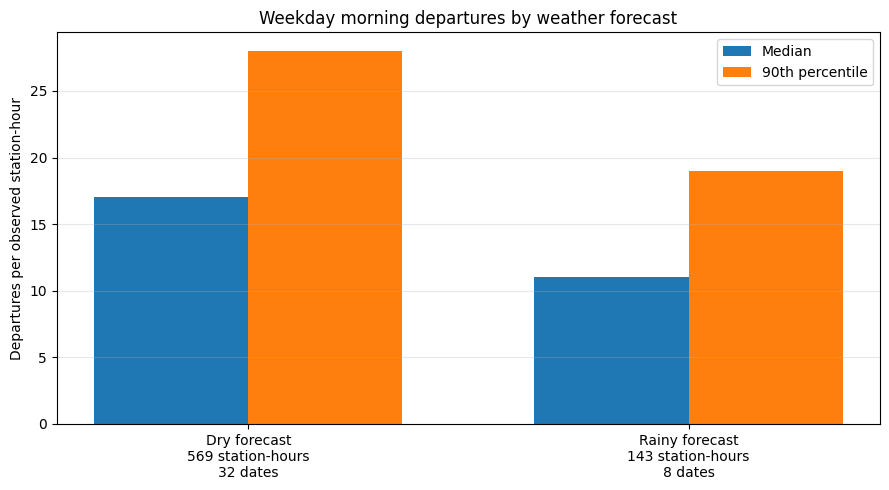

In [16]:
x = np.arange(len(weather_summary))
bar_width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    x - bar_width / 2,
    weather_summary["median"],
    width=bar_width,
    label="Median"
)

ax.bar(
    x + bar_width / 2,
    weather_summary["p90"],
    width=bar_width,
    label="90th percentile"
)

labels = [
    f"{row.weather}\n"
    f"{row.station_hours} station-hours\n"
    f"{row.distinct_dates} dates"
    for row in weather_summary.itertuples(index=False)
]

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set(
    title="Weekday morning departures by weather forecast",
    ylabel="Departures per observed station-hour"
)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()